# Рекомендательная система для e-commerce: описание данных и генерация факторов

**Этап итогового проекта (SkillFactory).** Цель всего проекта — сервис, который по идентификатору пользователя возвращает рекомендации товаров (с обёрткой в Docker и документацией).

В этом ноутбуке:
1. уточняем постановку задачи и метрики;
2. описываем структуру данных и проводим статистический анализ (EDA);
3. разбиваем данные по времени на train/test (без утечки будущего);
4. генерируем факторы: **айтемы**, **пользователи**, **пара пользователь–айтем**;
5. формируем целевую переменную и сохраняем датасеты для следующего этапа (коллаборативная фильтрация, факторизационные машины, XGBoost).

## 1. Постановка задачи

**Бизнес-задача.** Повысить конверсию интернет-магазина, показывая пользователю товары, которые он с наибольшей вероятностью добавит в корзину / купит.

**ML-постановка.** Для пары (пользователь, товар) предсказываем вероятность целевого действия в будущем. Рекомендации = top-K товаров по этой вероятности. Данные содержат неявную обратную связь (просмотр < добавление в корзину < покупка), явных оценок нет.

**Целевая переменная** (раздел 7): пользователь *добавил в корзину или купил* товар в тестовом периоде.

**Метрики качества.**
- Офлайн (ранжирование): `Precision@K`, `Recall@K`, `MAP@K`, `NDCG@K` при K = 5/10.
- Для классификатора (XGBoost): `ROC-AUC`, `PR-AUC` (классы сильно несбалансированы).
- Бизнес-метрики (для A/B): CTR рекомендаций, конверсия в корзину/покупку.

**Валидация.** Только по времени: фичи строятся по прошлому (train), цель — по будущему (test). Случайный split дал бы утечку.

In [4]:
import warnings, gc, pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')


from google.colab import drive
drive.mount('/content/drive/')
DATA_DIR = Path('/content/drive/MyDrive/Colab Notebooks')
OUT_DIR = Path('/content/drive/MyDrive/Colab Notebooks/features')    # сюда сохраним результат
OUT_DIR.mkdir(exist_ok=True)
SAMPLE_FRAC = 1.0             # доля пользователей для отладки на слабой машине (например, 0.1); для финального прогона = 1.0

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


## 2. Загрузка данных

`item_properties` весит ~900 МБ (≈20 млн строк), поэтому читаем его чанками: попутно считаем статистику по всем свойствам, а в памяти оставляем только нужные (`categoryid`, `available`, `790`).

In [5]:
events = pd.read_csv(DATA_DIR / 'events.csv', dtype={'visitorid': 'int32', 'itemid': 'int32', 'event': 'category'})
if SAMPLE_FRAC < 1:   # отладочная подвыборка пользователей
    vis = events['visitorid'].drop_duplicates().sample(frac=SAMPLE_FRAC, random_state=42)
    events = events[events['visitorid'].isin(vis)].reset_index(drop=True)
categories = pd.read_csv(DATA_DIR / 'category_tree.csv')

KEEP_PROPS = {'categoryid', 'available', '790'}
prop_counts, kept = pd.Series(dtype='int64'), []
n_prop_rows = 0
for part in ['item_properties_part1.csv', 'item_properties_part2.csv']:
    for ch in pd.read_csv(DATA_DIR / part, chunksize=1_000_000, dtype={'property': 'str', 'value': 'str'}):
        n_prop_rows += len(ch)
        prop_counts = prop_counts.add(ch['property'].value_counts(), fill_value=0)
        kept.append(ch[ch['property'].isin(KEEP_PROPS)].astype({'itemid': 'int32'}))
prop_counts = prop_counts.astype('int64').sort_values(ascending=False)
properties = pd.concat(kept, ignore_index=True)
properties = properties[properties['itemid'].isin(events['itemid'].unique())]   # свойства только товаров из лога
del kept; gc.collect()
print('events:', events.shape, '| categories:', categories.shape,
      '| properties (всего строк):', n_prop_rows, '| properties (оставили):', properties.shape)

events: (2756101, 5) | categories: (1669, 2) | properties (всего строк): 20275902 | properties (оставили): (2669516, 4)


## 3. Структура данных

In [6]:
events['event'] = events['event'].astype(str)
events['datetime'] = pd.to_datetime(events['timestamp'], unit='ms')
properties['datetime'] = pd.to_datetime(properties['timestamp'], unit='ms')
events.info()
events.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 6 columns):
 #   Column         Dtype         
---  ------         -----         
 0   timestamp      int64         
 1   visitorid      int32         
 2   event          object        
 3   itemid         int32         
 4   transactionid  float64       
 5   datetime       datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int32(2), int64(1), object(1)
memory usage: 105.1+ MB


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106


In [7]:
print('Пропуски в events:'); print(events.isna().sum())
print('\nДубликаты строк events:', events.duplicated().sum())
print('Период:', events['datetime'].min(), '->', events['datetime'].max())
print('Пользователей:', events['visitorid'].nunique(), '| товаров:', events['itemid'].nunique())
print('\nТипы событий:'); print(events['event'].value_counts())
# transactionid должен быть заполнен только у покупок
print('\nДоля заполненного transactionid по типам событий:'); print(events.groupby('event')['transactionid'].apply(lambda s: s.notna().mean()))

Пропуски в events:
timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
datetime               0
dtype: int64

Дубликаты строк events: 460
Период: 2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000
Пользователей: 1407580 | товаров: 235061

Типы событий:
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

Доля заполненного transactionid по типам событий:
event
addtocart     0.0000
transaction   1.0000
view          0.0000
Name: transactionid, dtype: float64


**Что описывают файлы**

| Файл | Колонки | Описание |
|---|---|---|
| `events.csv` | timestamp, visitorid, event, itemid, transactionid | Лог поведения: `view` → `addtocart` → `transaction`. `transactionid` есть только у покупок. Время — unix, мс. |
| `category_tree.csv` | categoryid, parentid | Дерево категорий. У корневых категорий `parentid` пустой. |
| `item_properties_part1/2.csv` | timestamp, itemid, property, value | История значений свойств товара (значение меняется во времени). Свойства захешированы, кроме `categoryid` и `available`. |

In [8]:
print('Категорий:', len(categories), '| корневых:', categories['parentid'].isna().sum())
print('\nСвойства товаров: всего строк', n_prop_rows, '| различных свойств:', len(prop_counts))
print('Топ-10 свойств по числу записей:'); print(prop_counts.head(10))
properties.groupby('property')['itemid'].nunique().rename('уникальных товаров')

Категорий: 1669 | корневых: 25

Свойства товаров: всего строк 20275902 | различных свойств: 1104
Топ-10 свойств по числу записей:
property
888           3000398
790           1790516
available     1503639
categoryid     788214
6              631471
283            597419
776            574220
678            481966
364            476486
202            448938
dtype: int64


,уникальных товаров
property,
790,185246
available,185246
categoryid,185246


Свойство `790` — числовые значения вида `n15360.000` (префикс `n` = число). Судя по распределению (см. ниже), это **цена**; `available` — наличие товара (0/1); `categoryid` — идентификатор категории. Назначение `790` — гипотеза, подтвердить её по данным нельзя, но как числовой ценовой признак он полезен в любом случае.

In [9]:
price_raw = properties.loc[properties['property'] == '790', 'value']
price_num = pd.to_numeric(price_raw.str.lstrip('n'), errors='coerce')
print('790: доля числовых значений', price_num.notna().mean()); print(price_num.describe())
print('\navailable:'); print(properties.loc[properties['property'] == 'available', 'value'].value_counts(normalize=True))

790: доля числовых значений 1.0
count       1,251,428.0000
mean          133,027.4786
std         2,343,013.1952
min                 0.0000
25%            17,520.0000
50%            47,760.0000
75%           133,440.0000
max     1,199,999,999.8800
Name: value, dtype: float64

available:
value
0   0.5100
1   0.4900
Name: proportion, dtype: float64


## 4. Статистический анализ (EDA)

### 4.1 События и воронка

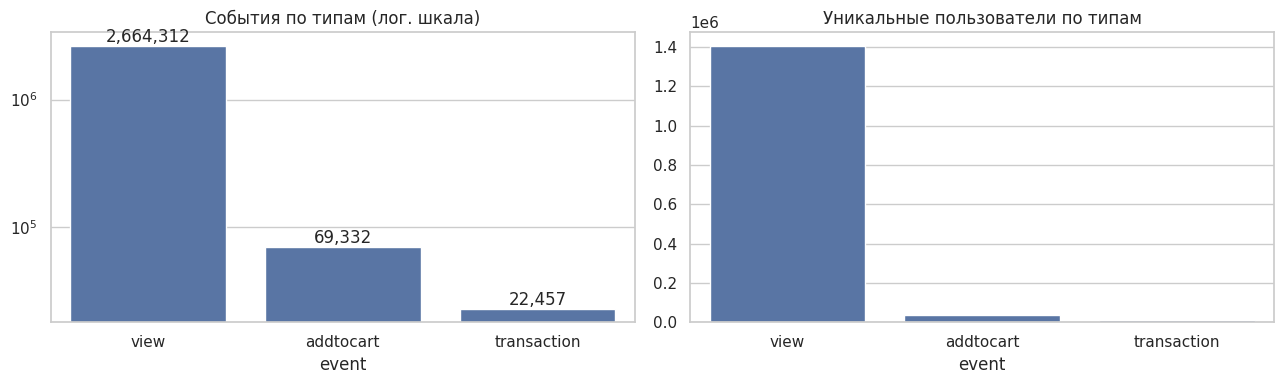

Воронка по пользователям (доля от view):
event
view          1.0000
addtocart     0.0269
transaction   0.0083
Name: visitorid, dtype: float64

Доля купленных пар (пользователь, товар), у которых есть view того же товара: 0.8956746591443348


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
cnt = events['event'].value_counts()
sns.barplot(x=cnt.index, y=cnt.values, ax=ax[0]); ax[0].set_yscale('log'); ax[0].set_title('События по типам (лог. шкала)')
for i, v in enumerate(cnt.values): ax[0].text(i, v, f'{v:,}', ha='center', va='bottom')
u = events.groupby('event')['visitorid'].nunique().reindex(['view', 'addtocart', 'transaction'])
sns.barplot(x=u.index, y=u.values, ax=ax[1]); ax[1].set_title('Уникальные пользователи по типам')
plt.tight_layout(); plt.show()

print('Воронка по пользователям (доля от view):'); print(u / u['view'])
buyers = events[events['event'] == 'transaction'][['visitorid', 'itemid']].drop_duplicates()
viewed = events[events['event'] == 'view'][['visitorid', 'itemid']].drop_duplicates()
m = buyers.merge(viewed, how='left', on=['visitorid', 'itemid'], indicator=True)
print('\nДоля купленных пар (пользователь, товар), у которых есть view того же товара:', (m['_merge'] == 'both').mean())

### 4.2 Временные закономерности

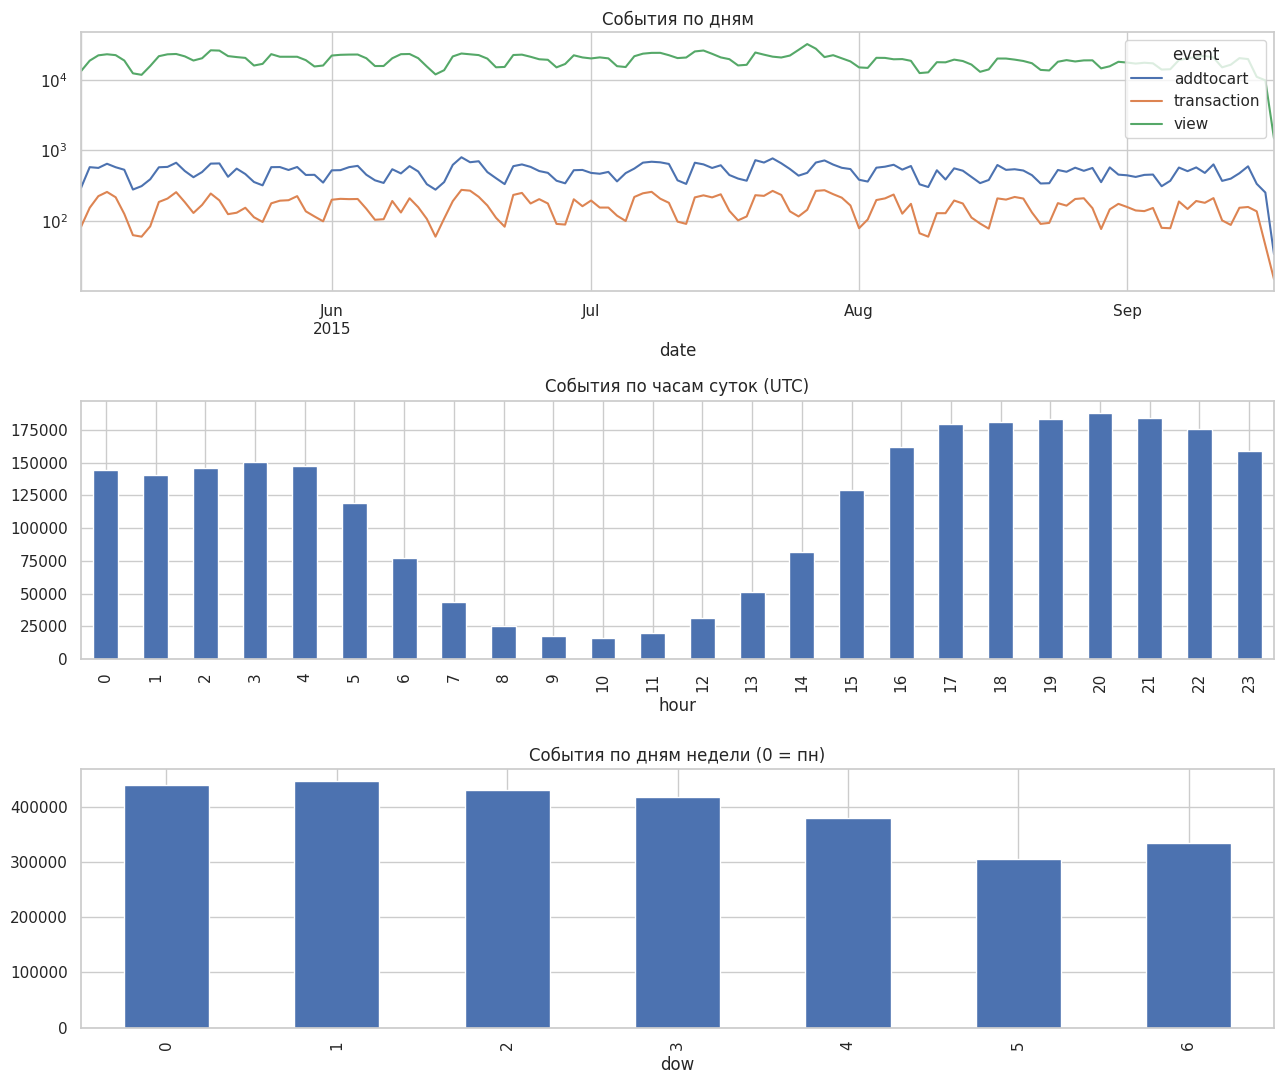

In [11]:
events['date'] = events['datetime'].dt.floor('D')
events['hour'] = events['datetime'].dt.hour
events['dow'] = events['datetime'].dt.dayofweek

fig, ax = plt.subplots(3, 1, figsize=(13, 11))
daily = events.groupby(['date', 'event']).size().unstack(fill_value=0)
daily.plot(ax=ax[0], logy=True, title='События по дням')
events.groupby('hour').size().plot.bar(ax=ax[1], title='События по часам суток (UTC)')
events.groupby('dow').size().plot.bar(ax=ax[2], title='События по дням недели (0 = пн)')
plt.tight_layout(); plt.show()

### 4.3 Активность пользователей и популярность товаров

События на пользователя:
count   1,407,580.0000
mean            1.9580
std            12.5805
min             1.0000
50%             1.0000
75%             2.0000
90%             3.0000
99%            13.0000
max         7,757.0000
dtype: float64

События на товар:
count   235,061.0000
mean         11.7250
std          37.0321
min           1.0000
50%           3.0000
75%           9.0000
90%          25.0000
99%         143.0000
max       3,412.0000
dtype: float64

Пользователей с 1 событием: 71.2%
Товаров с <=2 событиями: 46.1%


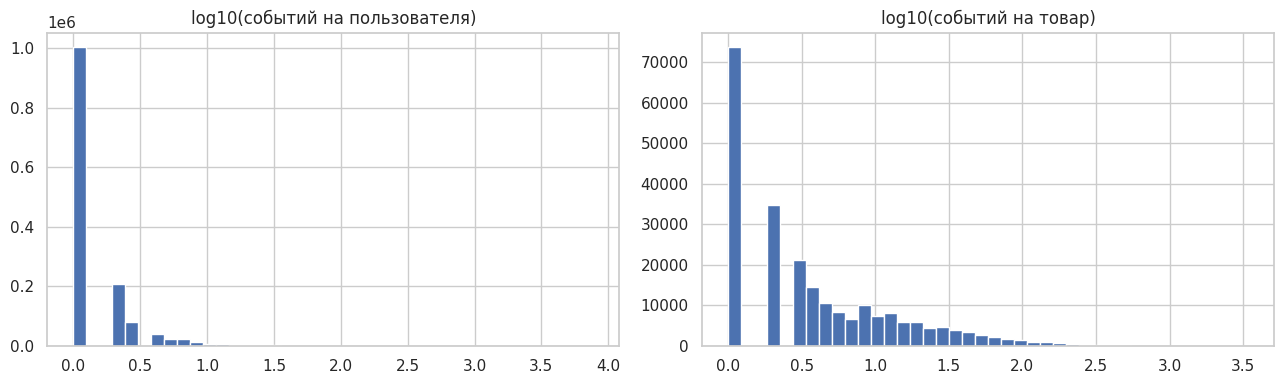

топ-1% товаров дают 23.0% событий
топ-5% товаров дают 49.3% событий
топ-20% товаров дают 78.7% событий


In [12]:
user_cnt = events.groupby('visitorid').size()
item_cnt = events.groupby('itemid').size()
print('События на пользователя:'); print(user_cnt.describe(percentiles=[.5, .75, .9, .99]))
print('\nСобытия на товар:'); print(item_cnt.describe(percentiles=[.5, .75, .9, .99]))
print(f'\nПользователей с 1 событием: {(user_cnt == 1).mean():.1%}')
print(f'Товаров с <=2 событиями: {(item_cnt <= 2).mean():.1%}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(np.log10(user_cnt), bins=40); ax[0].set_title('log10(событий на пользователя)')
ax[1].hist(np.log10(item_cnt), bins=40); ax[1].set_title('log10(событий на товар)')
plt.tight_layout(); plt.show()

# доля событий, приходящаяся на топ-N% товаров (long tail)
s = item_cnt.sort_values(ascending=False).cumsum() / item_cnt.sum()
for q in (0.01, 0.05, 0.2): print(f'топ-{q:.0%} товаров дают {s.iloc[int(len(s)*q)]:.1%} событий')

**Выводы.** Данные сильно разрежены: большинство пользователей — единичные визиты (холодный старт), распределение популярности товаров — «длинный хвост». Корзины и покупки — редкие события (~3 % от всех), поэтому целевая переменная будет сильно несбалансированной. Для пользователей без истории нужен fallback (популярное / по категории).

### 4.4 Дерево категорий и свойства товаров

In [13]:
parent = dict(zip(categories['categoryid'], categories['parentid']))

def path_to_root(c):
    path, seen = [c], {c}
    while c in parent and pd.notna(parent[c]) and int(parent[c]) not in seen:
        c = int(parent[c]); path.append(c); seen.add(c)
    return path

cat_info = pd.DataFrame({'categoryid': categories['categoryid']})
paths = cat_info['categoryid'].map(path_to_root)
cat_info['cat_depth'] = paths.map(len) - 1
cat_info['cat_root'] = paths.map(lambda p: p[-1])
cat_info['cat_parent'] = cat_info['categoryid'].map(parent)
cat_info['cat_n_children'] = cat_info['categoryid'].map(categories['parentid'].value_counts()).fillna(0).astype(int)
print('Распределение глубины:'); print(cat_info['cat_depth'].value_counts().sort_index())
print('Корней:', cat_info['cat_root'].nunique())
cat_info.head()

Распределение глубины:
cat_depth
0     25
1    174
2    702
3    665
4     90
5     13
Name: count, dtype: int64
Корней: 25


,categoryid,cat_depth,cat_root,cat_parent,cat_n_children
0,1016,3,1532,213.0000,0
1,809,3,395,169.0000,0
2,570,3,653,9.0000,0
3,1691,2,1579,885.0000,2
4,536,3,1579,"1,691.0000",0


In [14]:
# история свойств: сколько раз менялись значения
changes = properties.groupby(['itemid', 'property']).size().rename('n').reset_index()
print(changes.groupby('property')['n'].describe())
print('\nТоваров с известной категорией:', properties.loc[properties['property'] == 'categoryid', 'itemid'].nunique())
print('Доля товаров из events, для которых есть свойства:', events['itemid'].drop_duplicates().isin(properties['itemid']).mean())

                  count   mean    std    min    25%    50%     75%     max
property                                                                  
790        185,246.0000 6.7555 7.9269 1.0000 1.0000 1.0000 18.0000 18.0000
available  185,246.0000 5.4990 7.4054 1.0000 1.0000 1.0000 17.0000 18.0000
categoryid 185,246.0000 2.1562 4.2130 1.0000 1.0000 1.0000  1.0000 18.0000

Товаров с известной категорией: 185246
Доля товаров из events, для которых есть свойства: 0.7880762865809301


## 5. Разбиение train / test по времени

Фичи считаются **только по train**, цель — по test. Свойства товаров берём «как на момент отсечки» (последнее значение до `CUTOFF`), иначе просочится будущее.
Первые ~80 % событий по времени — train, остальные ~20 % — test.

In [15]:
CUTOFF = int(events['timestamp'].quantile(0.8))
CUTOFF_DT = pd.to_datetime(CUTOFF, unit='ms')
train = events[events['timestamp'] < CUTOFF].copy()
test = events[events['timestamp'] >= CUTOFF].copy()
print('cutoff:', CUTOFF_DT)
print('train:', train.shape, train['datetime'].min(), '->', train['datetime'].max())
print('test: ', test.shape, test['datetime'].min(), '->', test['datetime'].max())
print('\nПользователей в test, которых нет в train:', f"{(~test['visitorid'].drop_duplicates().isin(train['visitorid'])).mean():.1%}")
print('Товаров в test, которых нет в train:', f"{(~test['itemid'].drop_duplicates().isin(train['itemid'])).mean():.1%}")

cutoff: 2015-08-18 04:23:31.966000
train: (2204880, 9) 2015-05-03 03:00:04.384000 -> 2015-08-18 04:23:22.451000
test:  (551221, 9) 2015-08-18 04:23:31.966000 -> 2015-09-18 02:59:47.788000

Пользователей в test, которых нет в train: 92.0%
Товаров в test, которых нет в train: 19.4%


## 6. Генерация факторов

Все признаки считаются по `train`. Время «сейчас» = `CUTOFF`, поэтому «давность» измеряется относительно отсечки.

### 6.1 Факторы айтемов

In [16]:
H = 3_600_000          # мс в часе
D = 24 * H             # мс в сутках

def last_prop_before(prop, cutoff):
    p = properties[(properties['property'] == prop) & (properties['timestamp'] < cutoff)]
    return p.sort_values('timestamp').groupby('itemid')['value'].last()

# --- поведенческие факторы
piv = train.pivot_table(index='itemid', columns='event', values='timestamp', aggfunc='size', fill_value=0)
piv = piv.reindex(columns=['view', 'addtocart', 'transaction'], fill_value=0)
items = piv.rename(columns={'view': 'item_views', 'addtocart': 'item_carts', 'transaction': 'item_buys'})
items['item_events'] = items.sum(axis=1)
g = train.groupby('itemid')
items['item_users'] = g['visitorid'].nunique()
items['item_active_days'] = g['date'].nunique()
items['item_first_ts'] = g['timestamp'].min()
items['item_last_ts'] = g['timestamp'].max()
items['item_age_days'] = (CUTOFF - items['item_first_ts']) / D
items['item_days_since_last'] = (CUTOFF - items['item_last_ts']) / D
items['item_cart_rate'] = items['item_carts'] / items['item_views'].clip(lower=1)
items['item_buy_rate'] = items['item_buys'] / items['item_views'].clip(lower=1)
items['item_buy_per_cart'] = items['item_buys'] / items['item_carts'].clip(lower=1)
items['item_views_per_user'] = items['item_views'] / items['item_users']
rb = train[train['event'] == 'transaction'].groupby(['itemid', 'visitorid']).size()
items['item_repeat_buyers'] = (rb > 1).groupby('itemid').sum().reindex(items.index).fillna(0)
for w in (1, 7):   # динамика популярности за последние w суток
    recent = train[train['timestamp'] >= CUTOFF - w * D].groupby('itemid').size()
    items[f'item_events_last{w}d'] = recent.reindex(items.index).fillna(0)
items['item_trend_7d'] = items['item_events_last7d'] / items['item_events'].clip(lower=1)
items['item_mean_hour'] = g['hour'].mean()
items['item_pop_rank'] = items['item_events'].rank(ascending=False, pct=True)
items['item_buy_rank'] = items['item_buys'].rank(ascending=False, pct=True)

# --- факторы из свойств (на момент отсечки)
items['categoryid'] = pd.to_numeric(last_prop_before('categoryid', CUTOFF).reindex(items.index), errors='coerce')
items['item_available'] = pd.to_numeric(last_prop_before('available', CUTOFF).reindex(items.index), errors='coerce')
items['item_price'] = pd.to_numeric(last_prop_before('790', CUTOFF).reindex(items.index).str.lstrip('n'), errors='coerce')
items['item_log_price'] = np.log1p(items['item_price'])
pp = properties[(properties['timestamp'] < CUTOFF) & properties['property'].isin(['790', 'available'])]
items['item_price_changes'] = pp[pp['property'] == '790'].groupby('itemid').size().reindex(items.index).sub(1).clip(lower=0).fillna(0)
items['item_avail_changes'] = pp[pp['property'] == 'available'].groupby('itemid').size().reindex(items.index).sub(1).clip(lower=0).fillna(0)

# --- факторы категории и дерева
items = items.reset_index().merge(cat_info, on='categoryid', how='left')
cat_stats = items.groupby('categoryid').agg(cat_items=('itemid', 'nunique'), cat_views=('item_views', 'sum'),
                                            cat_carts=('item_carts', 'sum'), cat_buys=('item_buys', 'sum'),
                                            cat_mean_price=('item_price', 'mean')).reset_index()
cat_stats['cat_buy_rate'] = cat_stats['cat_buys'] / cat_stats['cat_views'].clip(lower=1)
items = items.merge(cat_stats, on='categoryid', how='left')
items['item_price_vs_cat'] = items['item_price'] / items['cat_mean_price']
root_stats = items.groupby('cat_root')['item_events'].sum().rename('root_events')
items = items.merge(root_stats, on='cat_root', how='left')
print(items.shape); items.head()

(212915, 40)


,itemid,item_views,item_carts,item_buys,item_events,item_users,item_active_days,item_first_ts,item_last_ts,item_age_days,item_days_since_last,item_cart_rate,item_buy_rate,item_buy_per_cart,item_views_per_user,item_repeat_buyers,item_events_last1d,item_events_last7d,item_trend_7d,item_mean_hour,item_pop_rank,item_buy_rank,categoryid,item_available,item_price,item_log_price,item_price_changes,item_avail_changes,cat_depth,cat_root,cat_parent,cat_n_children,cat_items,cat_views,cat_carts,cat_buys,cat_mean_price,cat_buy_rate,item_price_vs_cat,root_events
0,4,1,0,0,1,1,1,1435647791545,1435647791545,48.8891,48.8891,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,7.0000,0.8356,0.5237,"1,038.0000",0.0000,"468,360.0000",13.0570,0.0000,0.0000,3.0000,"1,532.0000","1,174.0000",0.0000,88.0000,393.0000,2.0000,2.0000,"68,316.5182",0.0051,6.8557,"261,040.0000"
1,6,27,0,0,27,24,22,1430944393122,1439228521479,103.3266,7.4455,0.0000,0.0000,0.0000,1.1250,0.0000,0.0000,0.0000,0.0000,13.3704,0.0824,0.5237,"1,091.0000",0.0000,"41,760.0000",10.6397,13.0000,13.0000,4.0000,"1,600.0000",573.0000,0.0000,191.0000,"2,262.0000",97.0000,27.0000,"33,088.7749",0.0119,1.2621,"289,813.0000"
2,9,2,0,0,2,2,2,1431557594505,1436405708315,96.2294,40.1169,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,11.5000,0.5953,0.5237,NaN,NaN,NaN,NaN,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,15,18,3,1,22,13,13,1432590641181,1437436979529,84.2728,28.1809,0.1667,0.0556,0.3333,1.3846,0.0000,0.0000,0.0000,0.0000,17.3636,0.1022,0.0316,722.0000,0.0000,"8,400.0000",9.0361,13.0000,13.0000,2.0000,653.0000,"1,110.0000",0.0000,17.0000,173.0000,3.0000,1.0000,"47,084.4706",0.0058,0.1784,"152,386.0000"
4,16,14,0,0,14,13,9,1430671507912,1439313708938,106.4850,6.4595,0.0000,0.0000,0.0000,1.0769,0.0000,0.0000,3.0000,0.2143,11.0714,0.1569,0.5237,333.0000,0.0000,"20,124.0000",9.9097,13.0000,13.0000,2.0000,"1,490.0000","1,497.0000",0.0000,981.0000,"17,660.0000",326.0000,72.0000,"69,932.0580",0.0041,0.2878,"73,198.0000"


In [ ]:
items.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]

### 6.2 Факторы пользователей

In [17]:
SESSION_GAP = 30 * 60 * 1000   # новая сессия, если пауза > 30 минут

tr = train.merge(items[['itemid', 'categoryid', 'cat_root', 'item_price']], on='itemid', how='left').sort_values(['visitorid', 'timestamp'])
tr['new_session'] = (tr.groupby('visitorid')['timestamp'].diff().fillna(SESSION_GAP + 1) > SESSION_GAP).astype(int)
tr['session_id'] = tr.groupby('visitorid')['new_session'].cumsum()

piv = tr.pivot_table(index='visitorid', columns='event', values='timestamp', aggfunc='size', fill_value=0)
piv = piv.reindex(columns=['view', 'addtocart', 'transaction'], fill_value=0)
users = piv.rename(columns={'view': 'user_views', 'addtocart': 'user_carts', 'transaction': 'user_buys'})
users['user_events'] = users.sum(axis=1)
g = tr.groupby('visitorid')
users['user_items'] = g['itemid'].nunique()
users['user_categories'] = g['categoryid'].nunique()
users['user_roots'] = g['cat_root'].nunique()
users['user_active_days'] = g['date'].nunique()
users['user_sessions'] = g['session_id'].max()
users['user_events_per_session'] = users['user_events'] / users['user_sessions']
users['user_first_ts'] = g['timestamp'].min()
users['user_last_ts'] = g['timestamp'].max()
users['user_days_since_first'] = (CUTOFF - users['user_first_ts']) / D
users['user_days_since_last'] = (CUTOFF - users['user_last_ts']) / D
users['user_span_days'] = (users['user_last_ts'] - users['user_first_ts']) / D
users['user_cart_rate'] = users['user_carts'] / users['user_views'].clip(lower=1)
users['user_buy_rate'] = users['user_buys'] / users['user_views'].clip(lower=1)
users['user_views_per_item'] = users['user_views'] / users['user_items']
users['user_mean_price'] = g['item_price'].mean()
users['user_median_price'] = g['item_price'].median()
users['user_mean_hour'] = g['hour'].mean()
users['user_night_share'] = tr.assign(n=tr['hour'].between(0, 5)).groupby('visitorid')['n'].mean()
users['user_weekend_share'] = tr.assign(w=tr['dow'] >= 5).groupby('visitorid')['w'].mean()
users['user_is_buyer'] = (users['user_buys'] > 0).astype(int)
users['user_is_single_event'] = (users['user_events'] == 1).astype(int)
users['user_top_category'] = tr.groupby(['visitorid', 'categoryid']).size().rename('n').reset_index() \
    .sort_values('n').groupby('visitorid')['categoryid'].last()
users = users.reset_index()
print(users.shape); users.head()

(1123767, 27)


event,visitorid,user_views,user_carts,user_buys,user_events,user_items,user_categories,user_roots,user_active_days,user_sessions,user_events_per_session,user_first_ts,user_last_ts,user_days_since_first,user_days_since_last,user_span_days,user_cart_rate,user_buy_rate,user_views_per_item,user_mean_price,user_median_price,user_mean_hour,user_night_share,user_weekend_share,user_is_buyer,user_is_single_event,user_top_category
0,1,1,0,0,1,1,1,1,1,1,1.0000,1439487966444,1439487966444,4.4427,4.4427,0.0000,0.0000,0.0000,1.0000,"354,960.0000","354,960.0000",17.0000,0.0000,0.0000,0,1,"1,192.0000"
1,2,8,0,0,8,4,2,1,1,1,8.0000,1438969904567,1438971657845,10.4387,10.4185,0.0203,0.0000,0.0000,2.0000,"50,355.0000","58,440.0000",17.6250,0.0000,0.0000,0,0,299.0000
2,3,1,0,0,1,1,1,1,1,1,1.0000,1438413035296,1438413035296,16.8840,16.8840,0.0000,0.0000,0.0000,1.0000,"13,680.0000","13,680.0000",7.0000,0.0000,1.0000,0,1,"1,171.0000"
3,5,1,0,0,1,1,1,1,1,1,1.0000,1437097556439,1437097556439,32.1094,32.1094,0.0000,0.0000,0.0000,1.0000,"294,120.0000","294,120.0000",1.0000,1.0000,0.0000,0,1,646.0000
4,7,3,0,0,3,3,2,1,2,2,1.5000,1431581976753,1431750039214,95.9472,94.0020,1.9452,0.0000,0.0000,1.0000,"21,673.8400","19,697.5200",4.6667,1.0000,0.3333,0,0,"1,114.0000"


### 6.3 Факторы пары пользователь–айтем

In [18]:
tr['is_cart'] = (tr['event'] == 'addtocart').astype(int)
tr['is_buy'] = (tr['event'] == 'transaction').astype(int)
tr['is_view'] = (tr['event'] == 'view').astype(int)

ui = tr.groupby(['visitorid', 'itemid']).agg(
    ui_views=('is_view', 'sum'), ui_carts=('is_cart', 'sum'), ui_buys=('is_buy', 'sum'),
    ui_first_ts=('timestamp', 'min'), ui_last_ts=('timestamp', 'max'), ui_days=('date', 'nunique')).reset_index()
ui['ui_events'] = ui['ui_views'] + ui['ui_carts'] + ui['ui_buys']
ui['ui_hours_since_last'] = (CUTOFF - ui['ui_last_ts']) / H
ui['ui_hours_since_first'] = (CUTOFF - ui['ui_first_ts']) / H
ui['ui_span_hours'] = (ui['ui_last_ts'] - ui['ui_first_ts']) / H
ui['ui_has_cart'] = (ui['ui_carts'] > 0).astype(int)
ui['ui_has_buy'] = (ui['ui_buys'] > 0).astype(int)
# последнее событие пары: 0 = view, 1 = addtocart, 2 = transaction
last_ev = tr.sort_values('timestamp').groupby(['visitorid', 'itemid'])['event'].last() \
    .map({'view': 0, 'addtocart': 1, 'transaction': 2}).rename('ui_last_event').reset_index()
ui = ui.merge(last_ev, on=['visitorid', 'itemid'])
# порядок товаров в истории пользователя по свежести (1 = самый свежий)
ui['ui_recency_rank'] = ui.groupby('visitorid')['ui_last_ts'].rank(ascending=False, method='first')

# присоединяем факторы айтема и пользователя
ui = ui.merge(items, on='itemid', how='left').merge(users, on='visitorid', how='left')
ui['ui_share_of_user'] = ui['ui_events'] / ui['user_events']
ui['ui_share_of_item'] = ui['ui_events'] / ui['item_events']
ui['ui_price_vs_user'] = ui['item_price'] / ui['user_mean_price']

# аффинити пользователя к категории товара
uc = tr.groupby(['visitorid', 'categoryid']).size().rename('ui_cat_events').reset_index()
ui = ui.merge(uc, on=['visitorid', 'categoryid'], how='left')
ui['ui_cat_share'] = ui['ui_cat_events'] / ui['user_events']
ur = tr.groupby(['visitorid', 'cat_root']).size().rename('ui_root_events').reset_index()
ui = ui.merge(ur, on=['visitorid', 'cat_root'], how='left')
ui['ui_root_share'] = ui['ui_root_events'] / ui['user_events']
ui['ui_is_top_category'] = (ui['categoryid'] == ui['user_top_category']).astype(int)
print(ui.shape)

(1713174, 89)


## 7. Целевая переменная

Кандидаты — пары (пользователь, товар), встречавшиеся в train. Положительный класс — пара, по которой в test есть `addtocart` или `transaction`. Дополнительно сохраняем отдельную метку покупки.

In [19]:
pos = test[test['event'].isin(['addtocart', 'transaction'])][['visitorid', 'itemid']].drop_duplicates().assign(target=1)
buy = test[test['event'] == 'transaction'][['visitorid', 'itemid']].drop_duplicates().assign(target_buy=1)
ui = ui.merge(pos, on=['visitorid', 'itemid'], how='left').merge(buy, on=['visitorid', 'itemid'], how='left')
ui[['target', 'target_buy']] = ui[['target', 'target_buy']].fillna(0).astype(int)
print('Пар в train:', len(ui))
print('Доля положительных (cart|buy):', ui['target'].mean(), '| buy:', ui['target_buy'].mean())

# потолок recall для кандидатов из истории
print('Доля test-пар (cart|buy), встречавшихся в train:', pos.merge(ui[['visitorid', 'itemid']], on=['visitorid', 'itemid']).shape[0] / len(pos))
print('Доля test-пар от пользователей без истории в train:', (~pos['visitorid'].isin(train['visitorid'])).mean())

Пар в train: 1713174
Доля положительных (cart|buy): 0.00021305483272568928 | buy: 0.00010915411978001068
Доля test-пар (cart|buy), встречавшихся в train: 0.026929319758005017
Доля test-пар от пользователей без истории в train: 0.8078795927401505


### 7.1 Проверка факторов: связь с целью

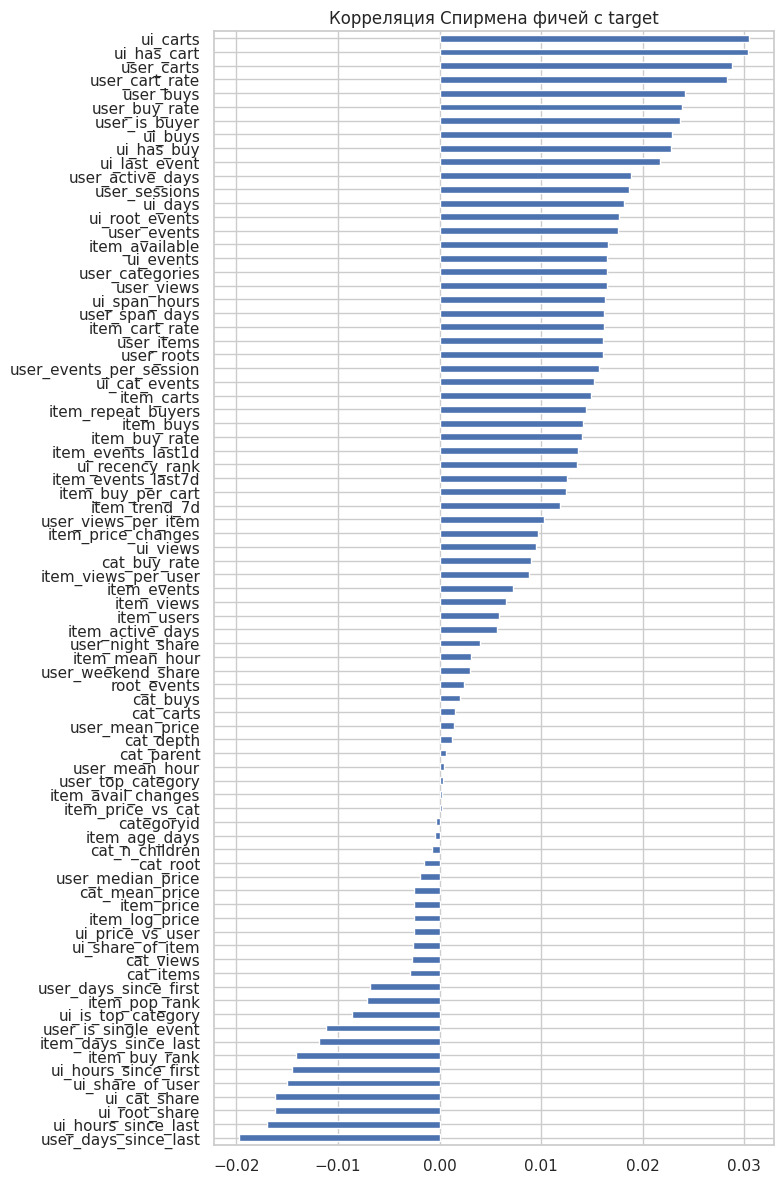

Топ-10 по |корреляции|:
ui_carts         0.0304
ui_has_cart      0.0303
user_carts       0.0288
user_cart_rate   0.0282
user_buys        0.0242
user_buy_rate    0.0239
user_is_buyer    0.0237
ui_buys          0.0228
ui_has_buy       0.0228
ui_last_event    0.0217
Name: target, dtype: float64


In [20]:
num_cols = [c for c in ui.columns if c not in ('visitorid', 'itemid', 'target', 'target_buy')
            and pd.api.types.is_numeric_dtype(ui[c]) and not c.endswith('_ts')]
corr = ui[num_cols + ['target']].corr(method='spearman')['target'].drop('target').sort_values()
plt.figure(figsize=(8, 12)); corr.plot.barh(); plt.title('Корреляция Спирмена фичей с target'); plt.tight_layout(); plt.show()
print('Топ-10 по |корреляции|:'); print(corr.reindex(corr.abs().sort_values(ascending=False).index).head(10))

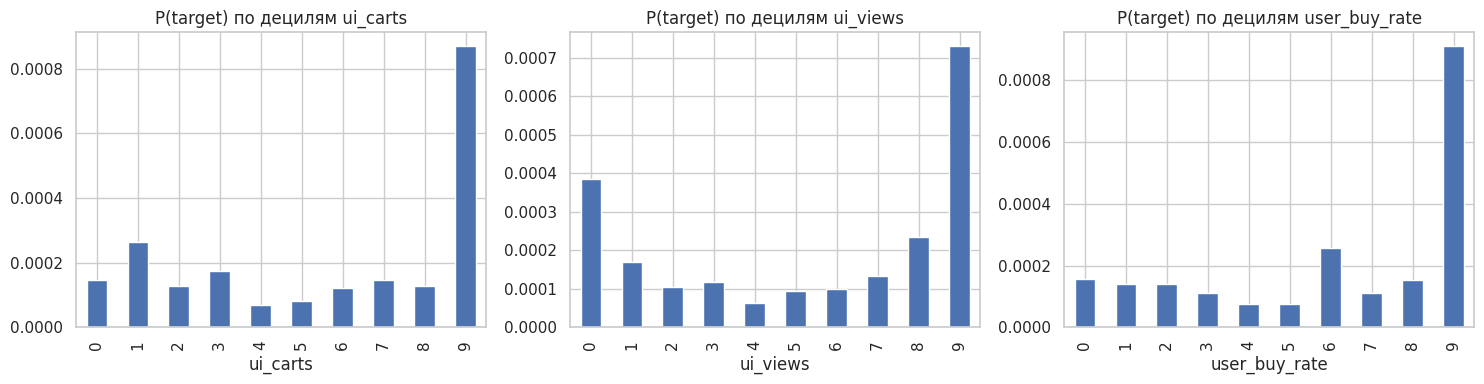

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ['ui_carts', 'ui_views', 'user_buy_rate']):
    ui.groupby(pd.qcut(ui[c].rank(method='first'), 10, labels=False))['target'].mean().plot.bar(ax=a, title=f'P(target) по децилям {c}')
plt.tight_layout(); plt.show()

## 8. Сохранение результатов

Сохраняем таблицы признаков для следующего этапа (эксперименты: коллаборативная фильтрация, факторизационные машины, XGBoost).

In [22]:
items.to_pickle(OUT_DIR / 'item_features.pkl')
users.to_pickle(OUT_DIR / 'user_features.pkl')
ui.to_pickle(OUT_DIR / 'user_item_features.pkl')
cat_info.to_pickle(OUT_DIR / 'category_info.pkl')
with open(OUT_DIR / 'meta.pkl', 'wb') as f:
    pickle.dump({'cutoff': CUTOFF}, f)
print({p.name: f'{p.stat().st_size / 1e6:.1f} MB' for p in OUT_DIR.iterdir()})

{'item_features.pkl': '67.3 MB', 'user_features.pkl': '238.2 MB', 'user_item_features.pkl': '1233.5 MB', 'category_info.pkl': '0.1 MB', 'meta.pkl': '0.0 MB'}


## 9. Итоги и следующие шаги

**Что сделано**
- описаны данные и проведён EDA: сильная разреженность, длинный хвост, редкие корзины/покупки, холодный старт;
- данные разделены по времени; фичи построены без утечки (по train, свойства — на момент отсечки);
- сгенерированы фичи: **айтемы** (популярность, конверсии, динамика, цена, наличие, категория), **пользователи** (активность, сессии, конверсии, ценовой профиль, время суток), **пара пользователь–айтем** (взаимодействия, давность, аффинити к категории);
- сформирована цель `target` и сохранены датасеты.

**Дальше (неделя 3):** коллаборативная фильтрация (implicit ALS / LightFM по матрице взаимодействий), факторизационные машины, XGBoost поверх фичей из этого ноутбука; оценка по Precision@K / MAP@K; затем API-сервис и Docker.